В лекции мы выяснили, что в эксперименте «Refactoring backend» в экспериментальной группе среднее время загрузки увеличилось, а 99% квантиль уменьшился. Проверьте значимость отличий других квантилей.

Данные эксперимента «Refactoring backend»: 2022-04-13/2022-04-13T12_df_web_logs.csv и 2022-04-13/experiment_users.csv. Эксперимент проводился с 2022-04-05 по 2022-04-12. Измерения времени обработки запросов считаем независимыми. При проверке используйте нормальный доверительный интервал.

Проверьте утверждения ниже.

In [32]:
import time
import os

import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.stats import norm, ttest_ind
from datetime import datetime
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

In [33]:
URL_BASE = 'https://raw.githubusercontent.com/ab-courses/simulator-ab-datasets/main'

def read_database(file_name):
    return pd.read_csv(os.path.join(URL_BASE, file_name))

web_logs = read_database('2022-04-13/2022-04-13T12_df_web_logs.csv')
web_logs['date'] = pd.to_datetime(web_logs['date'])
web_logs.head(3)


,user_id,page,date,load_time
0,f25239,m,2022-02-03 23:45:37,80.8
1,06d6df,m,2022-02-03 23:49:56,70.5
2,06d6df,m,2022-02-03 23:51:16,89.7


In [34]:
begin_date = datetime(2022, 4, 5)
end_date = datetime(2022, 4, 12)

df_logs = web_logs[(web_logs['date'] >= begin_date) & (web_logs['date'] < end_date)]
df_logs.shape

(252700, 4)

In [35]:
df_users = read_database('2022-04-13/experiment_users.csv')
df_users.head(3)

,user_id,pilot
0,c36b2e,0
1,20336e,0
2,034652,0


In [36]:
df = pd.merge(df_logs, df_users, on='user_id', how='left').fillna(0)
df.shape

(252700, 5)

web-logs — таблица с логами посещения сайта.

1. user_id — идентификатор пользователя;
2. page — какая страница сайта была открыта. Типы страниц:
    + m — страница с меню;
    + b  — страница с корзиной и подтверждением заказа;
    + p — страница с оплатой заказа;
3. date — дата открытия страницы;
4. load_time — время загрузки страницы в миллисекундах.

**Предполагается, что данные независимы**

In [42]:
group_a = df[df['pilot'] == 0]
group_b = df[df['pilot'] == 1]

load_time_a = group_a['load_time'].values
load_time_b = group_b['load_time'].values

In [38]:
def get_point_estimate(a_group, b_group, quantile=0.999):
    return np.quantile(b_group, quantile) - np.quantile(a_group, quantile)

In [39]:
def get_ci_bootstrap_normal(boot_metrics: np.array, pe_metric: float, alpha: float=0.05):
    """Строит нормальный доверительный интервал.

    boot_metrics - значения метрики, полученные с помощью бутстрепа
    pe_metric - точечная оценка метрики
    alpha - уровень значимости
    
    return: (left, right) - границы доверительного интервала.
    """
    c = stats.norm.ppf(1 - alpha / 2)
    se = np.std(boot_metrics)
    left, right = pe_metric - c * se, pe_metric + c * se
    return left, right

In [ ]:
def check_suggestion(a_group, b_group, quantile):
    point_estimate = get_point_estimate(load_time_a, load_time_b, quantile)
    print(point_estimate)

    bs_point_estimates = []
    for _ in range(1000):
        bs_a = np.random.choice(a_group, size=len(a_group), replace=True)
        bs_b = np.random.choice(b_group, size=len(b_group), replace=True)
        bs_point_estimate = get_point_estimate(bs_a, bs_b, quantile)
        bs_point_estimates.append(bs_point_estimate)

    normal_ci = get_ci_bootstrap_normal(bs_point_estimates, point_estimate)
    plt.title(f'{quantile * 100:.1f}% percentile difference')
    plt.hist(bs_point_estimates, bins=20);
    plt.vlines(normal_ci, 0, 100, label='normal CI', color='red')
    plt.legend()
    plt.show()

In [56]:
# Проверяем утверждения
# 1) Квантиль 0.70 статистически значимо изменился
#print(group_a.head())
#print(group_b.head())

1.0


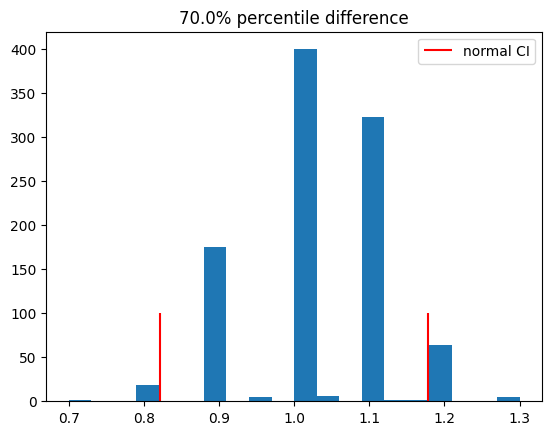

In [54]:
check_suggestion(load_time_a, load_time_b, 0.7)

**Вывод**: 0 НЕ входит в доверительный интервал, различие статистически значимо

0.5999999999999943


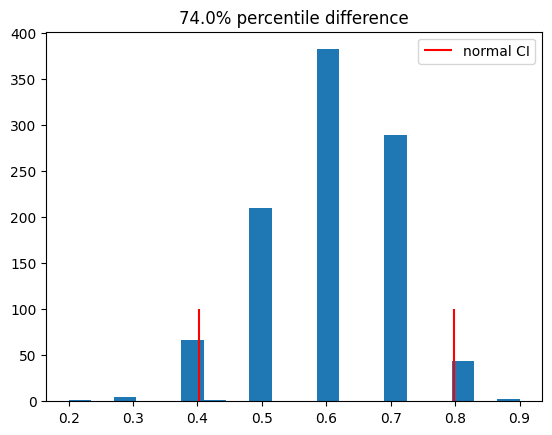

In [58]:
#2) Квантиль 0.74 статистически значимо изменился
check_suggestion(load_time_a, load_time_b, 0.74)

**Вывод**: 0 НЕ входит в доверительный интервал, различие статистически значимо

0.0


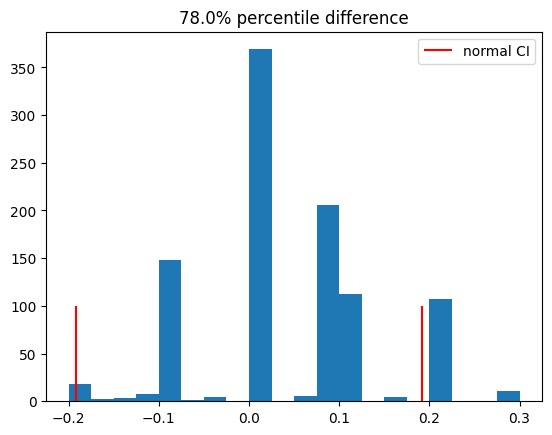

In [59]:
#3) Квантиль 0.78 статистически значимо изменился
check_suggestion(load_time_a, load_time_b, 0.78)

**Вывод**: 0 входит в доверительный интервал, различие НЕ статистически значимо

-0.5999999999999943


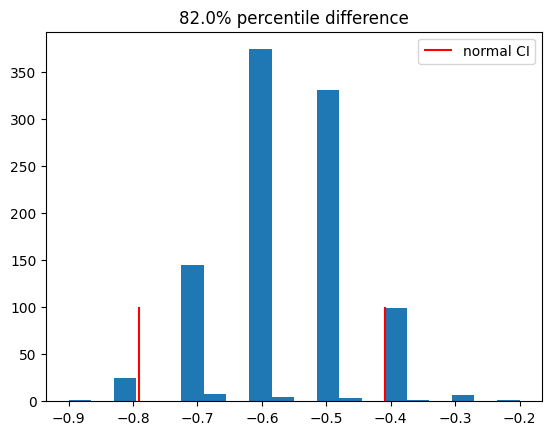

In [60]:
#4) Квантиль 0.82 статистически значимо изменился
check_suggestion(load_time_a, load_time_b, 0.82)

**Вывод**: 0 НЕ входит в доверительный интервал, различие статистически значимо

-1.2000000000000028


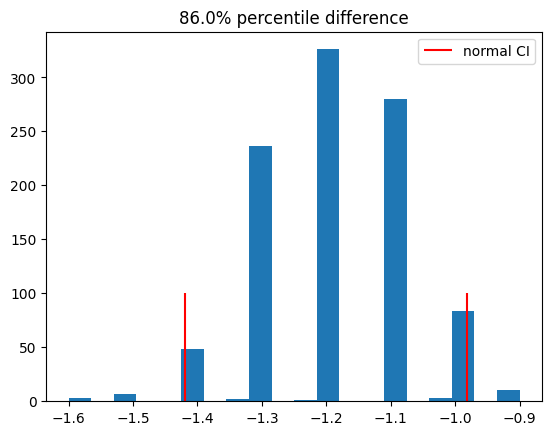

In [61]:
#5) Квантиль 0.86 статистически значимо изменился
check_suggestion(load_time_a, load_time_b, 0.86)

**Вывод**: 0 НЕ входит в доверительный интервал, различие статистически значимо

-2.0


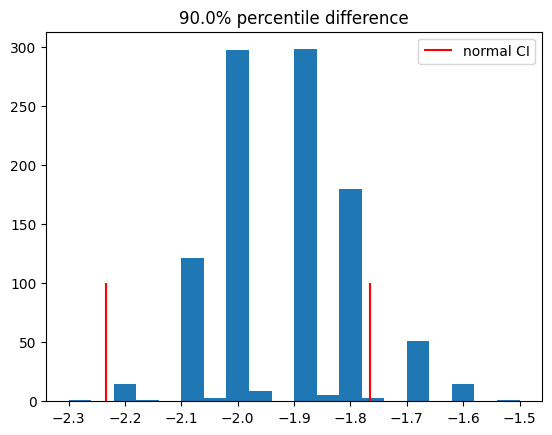

In [62]:
#6) Квантиль 0.90 статистически значимо изменился
check_suggestion(load_time_a, load_time_b, 0.90)

**Вывод**: 0 НЕ входит в доверительный интервал, различие статистически значимо

-3.299999999999997


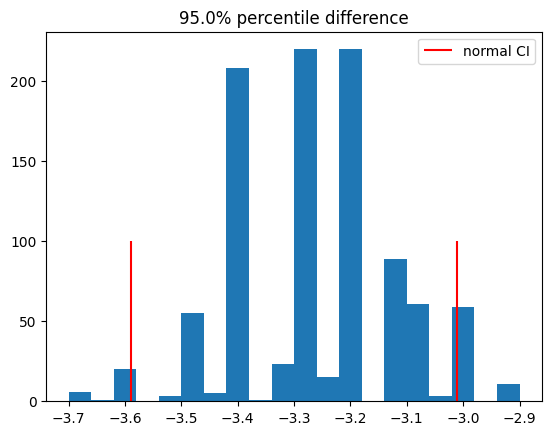

In [63]:
#7) Квантиль 0.95 статистически значимо изменился
check_suggestion(load_time_a, load_time_b, 0.95)

**Вывод**: 0 НЕ входит в доверительный интервал, различие статистически значимо

-6.300000000000011


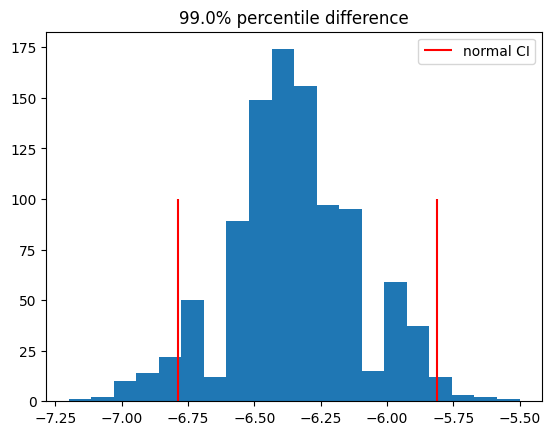

In [65]:
#8) Квантиль 0.99 статистически значимо изменился
check_suggestion(load_time_a, load_time_b, 0.99)

**Вывод**: 0 НЕ входит в доверительный интервал, различие статистически значимо

110.83279999986371


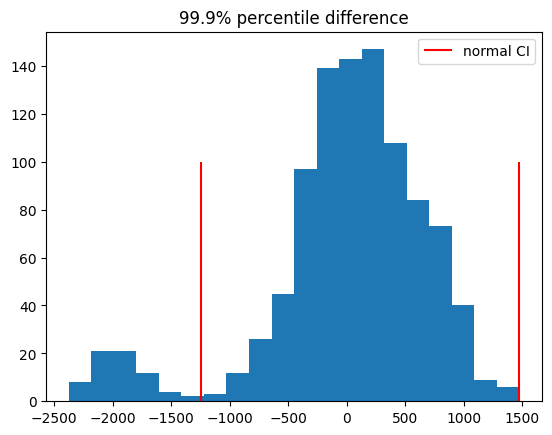

In [66]:
#9) Квантиль 0.999 статистически значимо изменился
check_suggestion(load_time_a, load_time_b, 0.999)

**Вывод**: 0 входит в доверительный интервал, различие НЕ статистически значимо

107.33312000002297


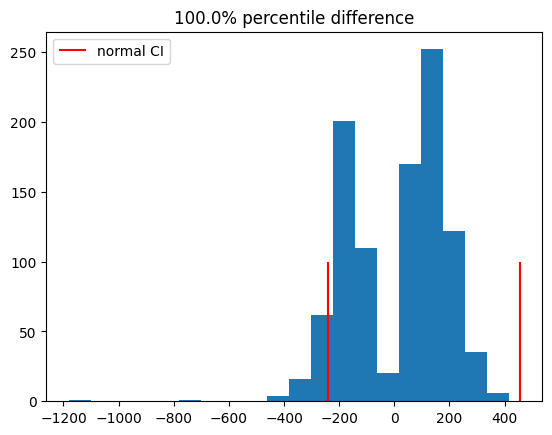

In [67]:
#10) Квантиль 0.9999 статистически значимо изменился
check_suggestion(load_time_a, load_time_b, 0.9999)

**Вывод**: 0  входит в доверительный интервал, различие НЕ статистически значимо

Итого НЕ верные утверждения:
3, 9, 10

ВСЕ остальнеы - верные